# NGBoost — Natural Gradient Boosting for Probabilistic Prediction

Notebook de demo para el Examen 2 (Presentación de Tema).

**Qué vamos a mostrar:**
1. Qué problema resuelve NGBoost (predicción con incertidumbre, no solo un número).
2. Un ejemplo de juguete en 1D que replica la idea central del paper (Figura 1).
3. Un ejemplo con datos reales (California housing), comparando NGBoost contra un Gradient Boosting clásico de scikit-learn.
4. Qué devuelve el modelo "por dentro" (los parámetros de la distribución).

**Fuentes:**
- Paper original: Duan, Avati, Ding, Thai, Basu, Ng, Schuler (2019). *NGBoost: Natural Gradient Boosting for Probabilistic Prediction*. [arXiv:1910.03225](https://arxiv.org/abs/1910.03225)
- Repo oficial: [stanfordmlgroup/ngboost](https://github.com/stanfordmlgroup/ngboost)


## 0. Instalación

Si corrés esto en Google Colab, descomentá la siguiente línea.


In [23]:
# Instala la librería ngboost (y sus dependencias: numpy, scipy, scikit-learn, etc.)
# !pip install ngboost


In [24]:
# Librerías para manejar arrays y graficar
import numpy as np
import matplotlib.pyplot as plt

# Utilidades de scikit-learn: separar train/test, cargar el dataset, el modelo
# "clásico" de comparación, y la métrica de error
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error

# NGBRegressor: el modelo de NGBoost para regresión.
# Normal: la distribución que vamos a boostear (predice μ y σ de una Normal).
from ngboost import NGBRegressor
from ngboost.distns import Normal

# Semilla fija para que los resultados sean reproducibles
rng = np.random.default_rng(42)


## 1. La idea central, en un ejemplo de juguete

Un modelo de regresión clásico predice *un número* por cada `x`. NGBoost predice una **distribución completa**: en este caso, una Normal con media `μ` (dónde creo que está el valor) y desvío `σ` (cuán seguro estoy).

Generamos datos sintéticos con **ruido heterocedástico**: el ruido crece a medida que `x` aumenta. Un buen modelo probabilístico debería notar esto y devolver una banda de incertidumbre que se **ensancha** junto con el ruido real — así como la Figura 1 del paper.


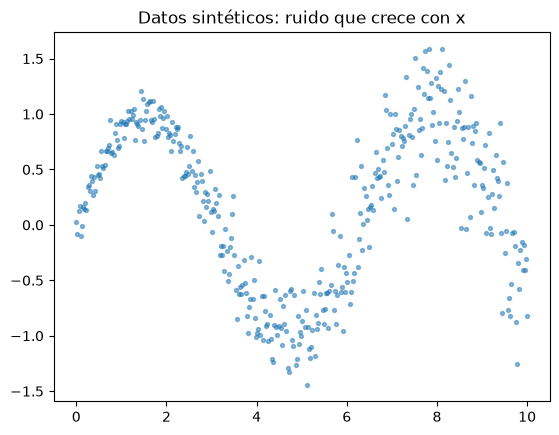

In [25]:
# Generamos un dataset sintético de juguete: x entre 0 y 10
n = 400
x = np.linspace(0, 10, n)

# El desvío del ruido crece a medida que x aumenta (heterocedasticidad):
# cerca de x=0 el ruido es chico, cerca de x=10 es mucho más grande.
noise_std = 0.1 + 0.3 * (x / 10)

# y = seno(x) + ruido (cuyo tamaño depende de x)
y = np.sin(x) + rng.normal(0, noise_std)
X = x.reshape(-1, 1)   # sklearn/ngboost esperan X como matriz (n_muestras, n_features)

# Visualizamos los datos crudos antes de entrenar nada
plt.scatter(x, y, s=8, alpha=0.5)
plt.title("Datos sintéticos: ruido que crece con x")
plt.show()


In [26]:
# Creamos el modelo NGBoost:
# - Dist=Normal      -> va a predecir una distribución Normal (μ, σ) por cada x
# - n_estimators=300 -> cantidad de rondas de boosting (árboles a sumar)
# - learning_rate    -> qué tan grande es cada paso de corrección
ngb_toy = NGBRegressor(
    Dist=Normal,
    n_estimators=300,
    learning_rate=0.02,
    verbose=False,
    random_state=42,
)

# Entrenamos con los datos sintéticos (igual que .fit() de cualquier modelo de sklearn)
ngb_toy.fit(X, y)


,n_estimators,300
,learning_rate,0.02
,verbose,False
,random_state,RandomState(M...at 0x2A9DC8040
,Dist,<class 'ngboo...ormal.Normal'>
,Score,<class 'ngboo...res.LogScore'>
,Base,DecisionTreeR...r(max_depth=3)
,natural_gradient,True
,minibatch_frac,1.0
,col_sample,1.0
,verbose_eval,100


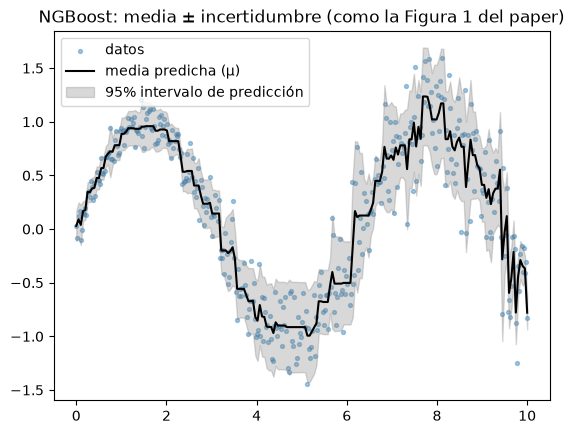

In [27]:
# Grilla de puntos nuevos donde vamos a predecir, para dibujar una curva suave
x_grid = np.linspace(0, 10, 200).reshape(-1, 1)

# pred_dist() devuelve la distribución completa predicha para cada punto
# (no un solo número como predict())
dist = ngb_toy.pred_dist(x_grid)

mean = dist.params["loc"]      # el μ predicho (centro de la distribución)
std = dist.params["scale"]     # el σ predicho (qué tan ancha es la incertidumbre)

# Graficamos: los datos, la media predicha, y la banda de 95% de confianza
# (±1.96 desvíos estándar, como un intervalo de confianza de una Normal)
fig, ax = plt.subplots()
ax.scatter(x, y, s=8, alpha=0.4, label="datos")
ax.plot(x_grid, mean, color="black", label="media predicha (μ)")
ax.fill_between(
    x_grid.ravel(), mean - 1.96 * std, mean + 1.96 * std,
    color="gray", alpha=0.3, label="95% intervalo de predicción",
)
ax.legend()
ax.set_title("NGBoost: media ± incertidumbre (como la Figura 1 del paper)")
plt.show()


**Qué mirar en el gráfico:** la banda gris es angosta cerca de `x=0` (poco ruido) y se va ensanchando hacia `x=10` (mucho ruido). NGBoost aprendió **ambos** patrones a la vez — la forma de la señal (`μ`) y cómo varía la incertidumbre (`σ`) — sin que se lo digamos explícitamente. Un Gradient Boosting clásico solo nos daría la línea negra, sin la banda gris.


## 2. Ejemplo con datos reales: California Housing

Ahora repetimos la idea con un dataset real (precios de casas en California, el mismo que usa el README oficial de NGBoost). Comparamos:

- **NGBoost** → predicción puntual + distribución completa + qué tan "sorprendido" está el modelo (NLL).
- **GradientBoostingRegressor (scikit-learn)** → solo predicción puntual, como referencia de un boosting clásico.


In [28]:
# Cargamos el dataset real: precios de casas en California (8 features numéricas, 1 target)
Xh, Yh = fetch_california_housing(return_X_y=True)

# Separamos test (20%) y, del resto, un set de validación (20%) para early stopping
Xh_train, Xh_test, Yh_train, Yh_test = train_test_split(Xh, Yh, test_size=0.2, random_state=42)
Xh_train, Xh_val, Yh_train, Yh_val = train_test_split(Xh_train, Yh_train, test_size=0.2, random_state=42)

print(f"train: {Xh_train.shape}, val: {Xh_val.shape}, test: {Xh_test.shape}")


train: (13209, 8), val: (3303, 8), test: (4128, 8)


In [29]:
# Mismo modelo que antes, pero ahora en un dataset real.
# learning_rate más chico porque hay más datos y más features.
ngb = NGBRegressor(
    Dist=Normal,
    n_estimators=300,
    learning_rate=0.01,
    verbose=False,
    random_state=42,
)

# Entrenamos usando el set de validación para hacer early stopping:
# si el modelo deja de mejorar en validación, corta antes de las 300 rondas
# (evita sobreajustar y ahorra tiempo de entrenamiento)
ngb.fit(Xh_train, Yh_train, X_val=Xh_val, Y_val=Yh_val, early_stopping_rounds=20)


,n_estimators,300
,verbose,False
,random_state,RandomState(M...at 0x2A880E540
,Dist,<class 'ngboo...ormal.Normal'>
,Score,<class 'ngboo...res.LogScore'>
,Base,DecisionTreeR...r(max_depth=3)
,natural_gradient,True
,learning_rate,0.01
,minibatch_frac,1.0
,col_sample,1.0
,verbose_eval,100


In [30]:
# predict() devuelve solo el punto estimado (la media de la distribución)
Y_preds = ngb.predict(Xh_test)

# pred_dist() devuelve la distribución completa para cada ejemplo de test
Y_dists = ngb.pred_dist(Xh_test)

# RMSE: error del punto predicho vs. el valor real (igual que cualquier regresión)
rmse_ngb = root_mean_squared_error(Yh_test, Y_preds)

# NLL (negative log-likelihood): mide qué tan "sorprendido" está el modelo con el
# valor real, dada la distribución que predijo. Cuanto más bajo, mejor calibrada
# está la incertidumbre (no solo el punto).
nll_ngb = -Y_dists.logpdf(Yh_test).mean()

print(f"NGBoost  -> RMSE: {rmse_ngb:.3f} | NLL: {nll_ngb:.3f}")


NGBoost  -> RMSE: 0.607 | NLL: 0.798


In [31]:
# Entrenamos un Gradient Boosting clásico de scikit-learn como punto de comparación:
# este modelo SOLO puede dar un número por predicción, no una distribución.
gbr = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)
gbr.fit(Xh_train, Yh_train)
Y_preds_gbr = gbr.predict(Xh_test)
rmse_gbr = root_mean_squared_error(Yh_test, Y_preds_gbr)

print(f"GBR (sklearn) -> RMSE: {rmse_gbr:.3f}   (no tiene forma de dar un NLL: no predice una distribución)")


GBR (sklearn) -> RMSE: 0.523   (no tiene forma de dar un NLL: no predice una distribución)


**Nota sobre el RMSE:** NGBoost no está optimizado para minimizar el error puntual (optimiza la verosimilitud de la distribución completa), así que es normal que un Gradient Boosting clásico le gane un poco en RMSE — el paper reporta exactamente este comportamiento ("within striking distance"). Lo que NGBoost ofrece a cambio es el NLL y, sobre todo, la banda de incertidumbre que el otro modelo no puede dar.


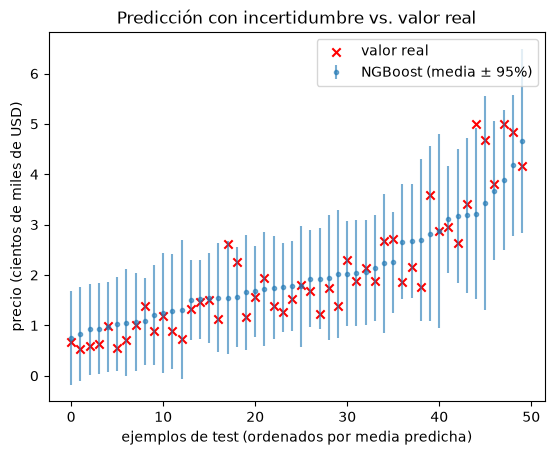

In [32]:
# Tomamos una muestra al azar del test set y la ordenamos por la media predicha,
# para visualizar cómo varía el intervalo de confianza caso a caso.
sample_idx = rng.choice(len(Yh_test), size=50, replace=False)
order = np.argsort(Y_preds[sample_idx])
idx = sample_idx[order]
positions = np.arange(len(idx))

means = Y_preds[idx]                      # medias predichas (ordenadas)
stds = Y_dists.params["scale"][idx]       # desvíos predichos para esos mismos ejemplos

# Graficamos: para cada ejemplo, la predicción con su barra de error (95%),
# y superponemos el valor real (cruz roja) para ver si cae dentro de la banda
fig, ax = plt.subplots()
ax.errorbar(positions, means, yerr=1.96 * stds, fmt="o", ms=3, alpha=0.6, label="NGBoost (media ± 95%)")
ax.scatter(positions, Yh_test[idx], color="red", marker="x", label="valor real")
ax.set_xlabel("ejemplos de test (ordenados por media predicha)")
ax.set_ylabel("precio (cientos de miles de USD)")
ax.legend()
ax.set_title("Predicción con incertidumbre vs. valor real")
plt.show()


**Qué mirar en el gráfico:** la mayoría de las cruces rojas (valor real) caen dentro de la banda azul (intervalo del 95%). Eso es lo que significa que el modelo esté "bien calibrado": no solo acierta en promedio, sino que su noción de incertidumbre es razonable.


## 3. Qué hay "adentro" de la predicción

`NGBRegressor` no devuelve un número: devuelve un objeto distribución. Sus parámetros son justamente el `θ = (μ, log σ)` del que habla el paper.


In [33]:
# Tomamos los primeros 5 ejemplos de test para ver "por dentro" qué devuelve el modelo.
# Y_dists es un objeto-distribución vectorizado: se puede indexar como un array.
ejemplo = Y_dists[:5]

# Estos son exactamente los parámetros θ = (μ, log σ) de los que habla el paper
print("medias (μ):", ejemplo.params["loc"])
print("desvíos (σ):", ejemplo.params["scale"])

# también podemos pedir percentiles, por ejemplo el intervalo 5%-95%
# (ppf = percent point function, la inversa de la función de distribución acumulada)
print("percentil 5%:", ejemplo.ppf(0.05))
print("percentil 95%:", ejemplo.ppf(0.95))


medias (μ): [0.80376566 1.08481922 3.52735095 2.59385099 2.20669656]
desvíos (σ): [0.47578906 0.54622343 1.28382504 0.50345094 0.65089945]
percentil 5%: [0.0211623  0.18636163 1.41564668 1.76574789 1.13606225]
percentil 95%: [1.58636902 1.98327681 5.63905522 3.4219541  3.27733088]


## 4. Conclusiones (para la presentación)

**Ventajas observadas en esta demo:**
- Con la misma API de scikit-learn (`.fit()` / `.predict()`), obtenemos no solo un número sino una distribución completa (`.pred_dist()`).
- El modelo aprende automáticamente que la incertidumbre varía según `x` (heterocedasticidad), sin que se lo digamos explícitamente.
- La calidad del punto predicho (RMSE) es competitiva con un boosting clásico, casi "gratis" junto con la incertidumbre.

**Limitaciones para mencionar:**
- Es más lento de entrenar que un Gradient Boosting clásico (entrena un learner por cada parámetro de la distribución).
- Si la distribución elegida (acá, Normal) no es la adecuada para los datos, la incertidumbre estimada puede ser mala — hay que elegir bien la distribución (`ngboost.distns`).
- Para quien solo le importa el punto (RMSE) y no la incertidumbre, un boosting clásico bien afinado sigue siendo preferible.
